# 3 · 网络 meta 分析（NMA）

!!! note "示例数据"
    这里用一个小型网络（4 个干预、5 个直接比较、两个环），目的是演示 API，
    不是真实临床结论。把 `TE/seTE` 换成你自己的数据即可。

NMA 要回答的是：**A、B、C、D 两两之间谁更好**，即使某些对子从来没有被直接比较过。


In [1]:
import numpy as np

import pimeta as ma

# 5 个直接比较。比值类指标要先取对数，再作为 TE 传进去。
TE = [0.30, -0.20, 0.90, 0.40, 0.10]
seTE = [0.12, 0.15, 0.18, 0.14, 0.13]
treat1 = ["A", "B", "A", "A", "B"]
treat2 = ["B", "C", "C", "D", "D"]
studlab = ["S1", "S2", "S3", "S4", "S5"]

print(f"{len(TE)} 个比较，涉及 {len(set(treat1) | set(treat2))} 个干预")

5 个比较，涉及 4 个干预


## 拟合网络

`netmeta()` 默认同时给 frequentist 的固定效应与随机效应结果。

In [2]:
nm = ma.netmeta(TE, seTE, treat1, treat2, studlab, sm="RR")

print("干预       :", list(nm.trts))
print("比较数 m   :", nm.m)
print(f"tau^2      : {nm.tau2:.5f}")
print(f"总 Q       : {nm.Q:.4f} (df={nm.df_Q:g}, p={nm.pval_Q:.4f})")
print(f"  └ 异质性 : {nm.Q_heterogeneity:.4f}")
print(f"  └ 不一致 : {nm.Q_inconsistency:.4f}")

干预       : ['A', 'B', 'C', 'D']
比较数 m   : 5
tau^2      : 0.07817
总 Q       : 9.8120 (df=2, p=0.0074)
  └ 异质性 : 0.0000
  └ 不一致 : 9.8120


## 相对效应是一个 n×n 矩阵

和 R 的 `$TE.random` 一样，矩阵第 `[i, j]` 元就是干预 `j` 相对干预 `i` 的效应（对角线上是 `nan`）。

In [3]:
import pandas as pd

n = len(nm.trts)
mat = pd.DataFrame(np.asarray(nm.TE_random, dtype=float),
                   index=[f"vs {t}" for t in nm.trts], columns=nm.trts)
print(mat.round(4).to_string())

           A       B       C       D
vs A     NaN  0.4828  0.5769  0.4927
vs B -0.4828     NaN  0.0942  0.0099
vs C -0.5769 -0.0942     NaN -0.0843
vs D -0.4927 -0.0099  0.0843     NaN


## 排名：P-score

In [4]:
rk = ma.netrank(nm)

score = pd.Series(np.asarray(rk.pscore_random, dtype=float),
                  index=nm.trts).sort_values(ascending=False)
print("P-score（1 = 最好，0 = 最差）")
print(score.round(4).to_string())

P-score（1 = 最好，0 = 最差）
C    0.7459
D    0.6296
B    0.6081
A    0.0163


## 联赛表（league table）

`netleague()` 返回的是 R 里那种**已经排好版的字符串矩阵**：对角线是干预名，
**下三角是网络估计**，**上三角是直接比较**（metafor/netmeta 的约定）。

In [5]:
lg = ma.netleague(nm)
print("干预顺序:", list(lg.trts))
print()
print(pd.DataFrame(lg.random, index=nm.trts, columns=nm.trts).to_string())
print()
print(lg.details)

干预顺序: ['A', 'B', 'C', 'D']

                           A                          B                           C                          D
A                          A  0.3000 [-0.2963;  0.8963]   0.9000 [ 0.2483;  1.5517]  0.4000 [-0.2128;  1.0128]
B  0.4828 [ 0.0522;  0.9133]                          B  -0.2000 [-0.8219;  0.4219]  0.1000 [-0.5043;  0.7043]
C  0.5769 [ 0.0737;  1.0801]  0.0942 [-0.4003;  0.5886]                           C                          .
D  0.4927 [ 0.0102;  0.9752]  0.0099 [-0.4699;  0.4897]  -0.0843 [-0.7068;  0.5383]                          D


Lower triangle: results from network meta-analysis (column vs row)
Upper triangle: results from direct comparisons (row vs column)



## 一致性：直接证据 vs 间接证据

每个比较拆成直接部分和间接部分，两者不一致说明网络内部有矛盾。

In [6]:
sp = ma.netsplit(nm)
table = pd.DataFrame({
    "比较": sp.comparison,
    "k": sp.k,
    "直接": pd.to_numeric(pd.Series(sp.direct_random["TE"]), errors="coerce"),
    "间接": pd.to_numeric(pd.Series(sp.indirect_random["TE"]), errors="coerce"),
})
print(table.round(4).to_string(index=False))
print()
print("（C:D 的'直接'是 NaN：这一对从来没有被直接比较过，"
      "它的估计完全来自网络 —— 这正是 NMA 的价值。）")

 比较  k   直接      间接
A:B  1  0.3  0.6818
A:C  1  0.9  0.1000
A:D  1  0.4  0.6438
B:C  1 -0.2  0.6000
B:D  1  0.1 -0.1438
C:D  0  NaN -0.0843

（C:D 的'直接'是 NaN：这一对从来没有被直接比较过，它的估计完全来自网络 —— 这正是 NMA 的价值。）


## 排名：P-score 图

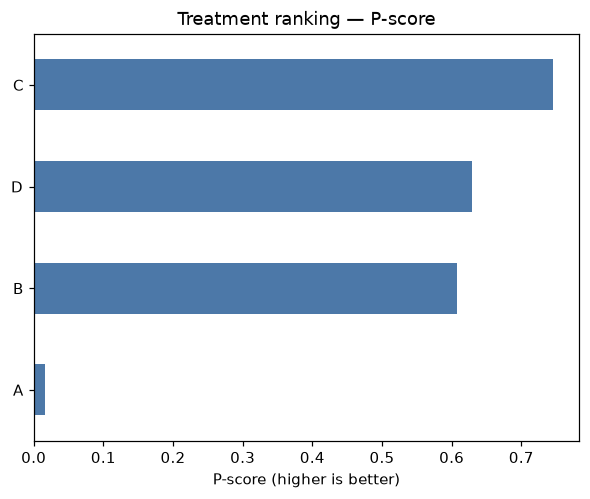

In [7]:
ax = score.sort_values().plot.barh(color="#4c78a8")
ax.set_xlabel("P-score (higher is better)")
_ = ax.set_title("Treatment ranking — P-score")

## 热图：不一致性到底出在哪里

`netheat()` 的每一格是「把第 *j* 个设计拿掉之后，第 *i* 个设计对剩下不一致性的贡献」。
行里特别突出（或特别负）的设计，就是把这个环的矛盾担得最多的那个。

（不是凭空算的：`pimeta.netmeta.netheat_matrix()` 直接转录 R `netheat()` 的内部公式，
数值已和 R 逐格对拍。）

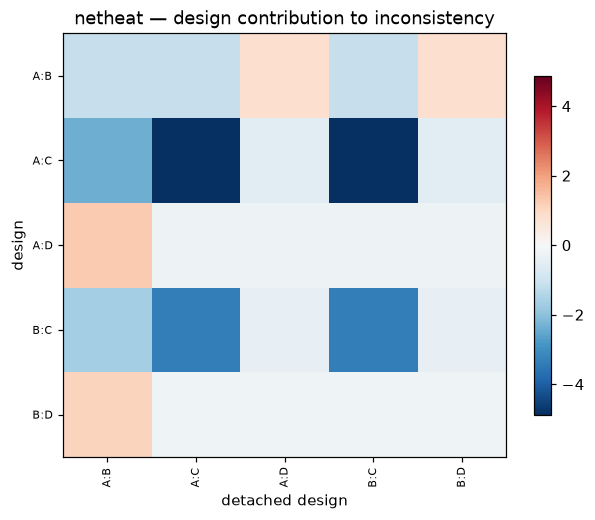

In [8]:
plot = ma.netheat(nm)
_ = plot.ax.set_title("netheat — design contribution to inconsistency")

## 小结

| 想知道 | 用 |
|---|---|
| 两两相对效应 | `nm.TE_random[i, j]`（n×n 矩阵） |
| 谁最好 | `ma.netrank(nm).pscore_random` |
| 贴论文的联赛表 | `ma.netleague(nm).random` |
| 直接/间接是否一致 | `ma.netsplit(nm)` |
| 不一致性来源 | `ma.netheat(nm)` |

原始 2×2 数据可以用 `ma.netmetabin(event1, n1, event2, n2, treat1, treat2)` 直接喂，
它会在内部做 Mantel-Haenszel / 逆方差等合并。